### Week 8 notebook - K-Nearest Neighbors and Distance Metrics, Mod C Data Science Capstone Fall 2026
### By Shuqin Ouyang

# Overall notebook structure:



# Student dataset analysis starts here:

In [1]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.model_selection import StratifiedKFold, train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.inspection import permutation_importance

In [2]:
# same shuffled 5-fold CV as Week 6
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
KS = [1, 3, 5, 11, 21, 51]    # odd k, so a vote can never tie
METRICS = ['manhattan', 'euclidean', 'cosine']    # manhattan = Minkowski p=1, euclidean = p=2

# KNN pipeline: scale -> optionally cap z-scores -> vote of k nearest neighbors. 'passthrough' means the step is switched off
MODEL = Pipeline([('scale', StandardScaler()), ('cap', 'passthrough'), ('knn', KNeighborsClassifier(algorithm='brute', n_jobs=-1))])
CAP = FunctionTransformer(np.clip, kw_args={'a_min': -3, 'a_max': 3})    # no value counts as more than 3 std

Helper functions (used for both datasets):

In [3]:
def split_data(df, target):
    # same as Weeks 5 and 6: stratified 80/20 split
    df = df.dropna()
    return train_test_split(df.drop(columns=[target]), df[target], test_size=0.2, stratify=df[target], random_state=42)

def cv_f1(X, y, metric, k, **steps):
    # CV F1 of KNN with this formula and k; steps switches pipeline steps, e.g. scale='passthrough'
    model = clone(MODEL).set_params(knn__metric=metric, knn__n_neighbors=k, **steps)
    return cross_val_score(model, X, y, cv=CV, scoring='f1').mean()

Dataset 1 background quick overview:

The dataset 1 used is the Taiwanese Bankruptcy Prediction dataset from UCI, link as https://archive.ics.uci.edu/dataset/572/taiwanese+bankruptcy+prediction.
It contains company financial indicators and a binary outcome for bankruptcy.

In [4]:
# install uci package so can load the data using package
# install once in terminal or notebook

!pip install ucimlrepo

from ucimlrepo import fetch_ucirepo

# load dataset from UCI repository using dataset id
data_bankruptcy = fetch_ucirepo(id=572)

df_bankruptcy = pd.concat(
    [data_bankruptcy.data.features.copy(),
     data_bankruptcy.data.targets.copy()],
    axis=1
)

# remove leading/trailing spaces from column names once, here
df_bankruptcy.columns = df_bankruptcy.columns.str.strip()

df_bankruptcy.head()

'pip' is not recognized as an internal or external command,
operable program or batch file.


,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,Continuous interest rate (after tax),...,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability,Bankrupt?
0,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,0.780985,...,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469,1
1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,0.781506,...,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794,1
2,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,0.780284,...,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474,1
3,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,0.781241,...,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982,1
4,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,0.781550,...,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490,1


Student markdown:

Dataset 1 is the Taiwanese bankruptcy data: 6,819 companies described by 95 financial ratios, of which about 3.2% went bankrupt. All features are numeric and none are missing.

In [5]:
# stratified 80/20 split, all features. Small enough to tune on the full training set
X_train_bankrupt, X_test_bankrupt, y_train_bankrupt, y_test_bankrupt = split_data(df_bankruptcy, 'Bankrupt?')
X_tune_bankrupt, y_tune_bankrupt = X_train_bankrupt, y_train_bankrupt
p_bankrupt = y_test_bankrupt.mean()
print(len(X_train_bankrupt), "train rows,", len(X_test_bankrupt), "test rows. baseline F1 (predict every company fails):", round(2 * p_bankrupt / (1 + p_bankrupt), 3))

5455 train rows, 1364 test rows. baseline F1 (predict every company fails): 0.062


In [6]:
# EDA for KNN: are features on similar scales, and how many rows have an outlier (a value more than 3 std from its average)?
feature_std = X_train_bankrupt.std()
abs_z = ((X_train_bankrupt - X_train_bankrupt.mean()) / feature_std).abs()
has_outlier = (abs_z > 3).any(axis=1)
print(feature_std[feature_std > 0].agg(['min', 'max']))
print("share of rows with an outlier, by class (0 = no failure, 1 = failure):")
print(has_outlier.groupby(y_train_bankrupt).mean().round(2))

min    2.319257e-03
max    3.387366e+09
dtype: float64
share of rows with an outlier, by class (0 = no failure, 1 = failure):
Bankrupt?
0    0.27
1    0.48
dtype: float64


Student markdown:

I use all 95 features with a stratified 80/20 split (5,455 training rows and 1,364 test rows), and every step below tunes on the full training set. Because only about 3% of companies are bankrupt, I judge models with F1 and compare them with a lazy baseline that predicts every company fails. That baseline catches every real failure (recall = 1) but is right only as often as failures occur (precision = p, the failure rate), so its F1 is 2p / (1 + p), which is 0.062 here. The baseline rises when failures are more common (it is 0.362 at p = 0.22), so a higher F1 alone does not make a better model. What matters is the gain over a dataset's own baseline.

Before modeling, the EDA checks two things that matter for a distance-based model. The raw feature scales are very different (std from 0.002 to 3.4 billion), so without scaling a few huge columns would decide who counts as "near". And outliers are common, especially among bankrupt companies: 48% of them have at least one value more than 3 standard deviations from average, against 27% of healthy companies.

Step 1: let the search choose. Grid search tries every distance formula and k and keeps the best CV F1.

best: {'knn__metric': 'cosine', 'knn__n_neighbors': 3} | CV F1 0.298
 k  train F1  CV F1  CV std
 1     1.000  0.241   0.040
 3     0.524  0.298   0.058
 5     0.417  0.257   0.064
11     0.255  0.178   0.058
21     0.120  0.081   0.050
51     0.003  0.000   0.000


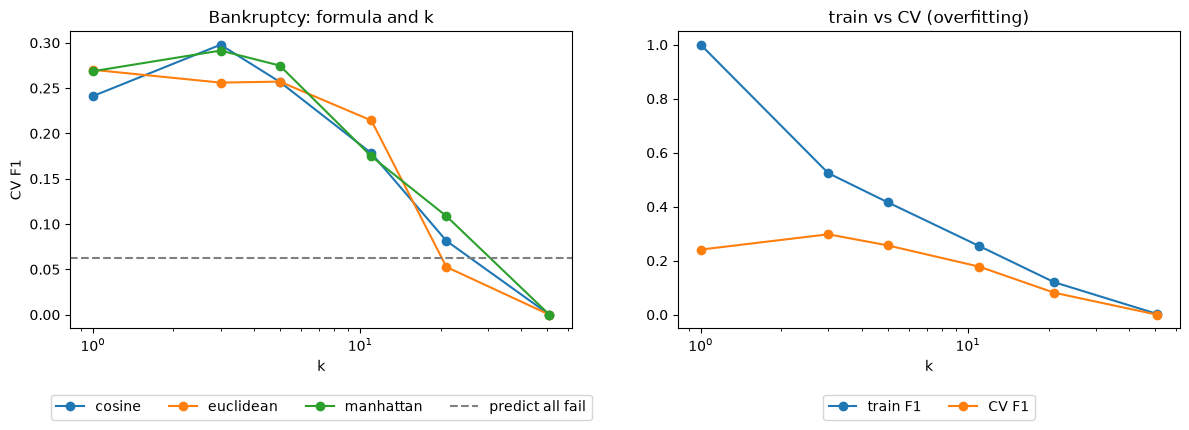

In [7]:
# grid search over distance formula and k, scaled data
grid_bankrupt = GridSearchCV(MODEL, {'knn__metric': METRICS, 'knn__n_neighbors': KS}, cv=CV, scoring='f1', return_train_score=True).fit(X_tune_bankrupt, y_tune_bankrupt)
res_bankrupt = pd.DataFrame(grid_bankrupt.cv_results_).rename(columns={'param_knn__metric': 'formula', 'param_knn__n_neighbors': 'k', 'mean_test_score': 'CV F1',
                       'mean_train_score': 'train F1', 'std_test_score': 'CV std'})
cv_table_bankrupt = res_bankrupt.pivot(index='k', columns='formula', values='CV F1')
best_bankrupt = grid_bankrupt.best_params_
print("best:", best_bankrupt, "| CV F1", round(grid_bankrupt.best_score_, 3))
print(res_bankrupt[(res_bankrupt.formula == best_bankrupt['knn__metric'])][['k', 'train F1', 'CV F1', 'CV std']].round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
cv_table_bankrupt.plot(ax=axes[0], logx=True, marker='o', ylabel='CV F1', title='Bankruptcy: formula and k')
axes[0].axhline(2 * p_bankrupt / (1 + p_bankrupt), color='gray', linestyle='--', label='predict all fail')
res_bankrupt[res_bankrupt.formula == best_bankrupt['knn__metric']].set_index('k')[['train F1', 'CV F1']].plot(ax=axes[1], logx=True, marker='o', title='train vs CV (overfitting)')
for ax in axes:
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=4)
plt.tight_layout()
plt.show()

Student markdown:

Step 1 lets grid search choose the distance formula and k. The best setting is Cosine with k=3 (CV F1 0.298), but the three formulas score about the same (Manhattan 0.29, Euclidean 0.27, Cosine 0.30) and the gap is smaller than the fold-to-fold variation (CV std about 0.04 to 0.06), so I cannot say one formula is better. k matters far more: CV F1 is 0.24 at k=1, 0.30 at k=3, 0.26 at k=5, 0.18 at k=11, 0.08 at k=21 and 0.00 at k=51.

The train vs CV chart shows why. At k=1 train F1 is 1.0, which is perfect by construction because every training point is its own nearest neighbor, while CV F1 is only 0.24. At k=3 the two are 0.52 and 0.30. The gap shrinks at larger k, but only because the model stops predicting bankruptcy at all, so I stop at k=3, the peak of CV F1.

Hypothesis A: scaling is needed for KNN.

           scaled  unscaled
manhattan   0.291     0.041
euclidean   0.270     0.110
cosine      0.298     0.040


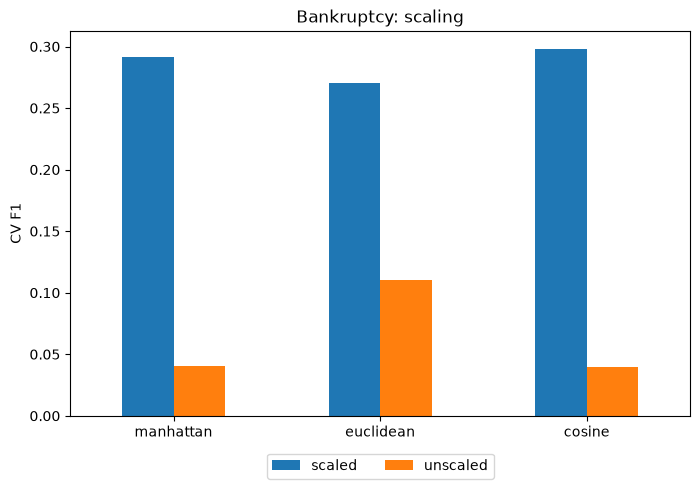

In [8]:
# each formula at its own best k, scaled (from the grid) vs not scaled
bestk_bankrupt = cv_table_bankrupt.idxmax()
A_bankrupt = pd.DataFrame({'scaled': cv_table_bankrupt.max(),
                      'unscaled': [cv_f1(X_tune_bankrupt, y_tune_bankrupt, m, bestk_bankrupt[m], scale='passthrough') for m in METRICS]}, index=METRICS)
print(A_bankrupt.round(3))
ax = A_bankrupt.plot.bar(rot=0, figsize=(8, 5), ylabel='CV F1', title='Bankruptcy: scaling')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=2)
plt.show()

Student markdown:

Using each formula's best k, Hypothesis A asks whether scaling is needed. Without it, F1 falls from 0.29 to 0.04 for Manhattan, from 0.27 to 0.11 for Euclidean and from 0.30 to 0.04 for Cosine. These drops are much bigger than the fold-to-fold variation, so scaling is clearly needed, which fits the huge scale differences seen in the EDA.

Hypothesis B: outliers hurt KNN, so capping z-scores at +/- 3 (no value counts as more than 3 standard deviations) should help, more for Euclidean (which squares each gap) than Manhattan.

           original  capped  change
manhattan     0.291   0.290  -0.001
euclidean     0.270   0.240  -0.031
cosine        0.298   0.331   0.034


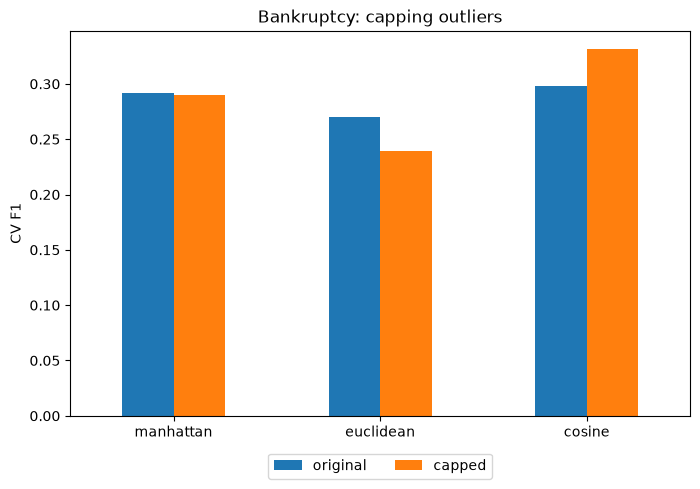

In [9]:
# same, with z-scores capped at +/- 3
B_bankrupt = pd.Series([cv_f1(X_tune_bankrupt, y_tune_bankrupt, m, bestk_bankrupt[m], cap=CAP) for m in METRICS], index=METRICS)
change_bankrupt = pd.DataFrame({'original': A_bankrupt['scaled'], 'capped': B_bankrupt})
change_bankrupt['change'] = change_bankrupt['capped'] - change_bankrupt['original']
print(change_bankrupt.round(3))
ax = change_bankrupt[['original', 'capped']].plot.bar(rot=0, figsize=(8, 5), ylabel='CV F1', title='Bankruptcy: capping outliers')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=2)
plt.show()

Student markdown:

With scaling in place, Hypothesis B asks whether capping outliers helps. Capping z-scores at +/- 3 changes Manhattan by -0.001, Euclidean by -0.031 and Cosine by +0.034 (CV F1 0.331). For Cosine, the formula I end up using, capping raises F1 by +0.034, but that is smaller than the CV std at k=3 (about 0.058), so I cannot call it a real gain. The Euclidean drop (-0.031) is about the same size as the noise too, although I only printed the std for Cosine and did not check it for the other formulas. So capping shows no clear effect here. The swings are larger than on credit card, which fits bankrupt companies having more outliers (48% vs 27%). A possible reason, which I did not test, is that these extreme values carry signal that capping removes. With this much noise, though, it is a hint, not a result.

In [10]:
# final model: best CV F1 over formula and original/capped, refit on the training set, tested once on the held-out 20%
cands_bankrupt = {(m, False): A_bankrupt.loc[m, 'scaled'] for m in METRICS} | {(m, True): B_bankrupt[m] for m in METRICS}
(metric_bankrupt, capped_bankrupt), cv_bankrupt = max(cands_bankrupt.items(), key=lambda kv: kv[1])
model_bankrupt = clone(MODEL).set_params(knn__metric=metric_bankrupt, knn__n_neighbors=bestk_bankrupt[metric_bankrupt], cap=CAP if capped_bankrupt else 'passthrough').fit(X_train_bankrupt, y_train_bankrupt)
pred_bankrupt = model_bankrupt.predict(X_test_bankrupt)
final_bankrupt = pd.Series({'formula': metric_bankrupt, 'capped': capped_bankrupt, 'k': bestk_bankrupt[metric_bankrupt], 'CV F1': round(cv_bankrupt, 3),
                       'test F1': f1_score(y_test_bankrupt, pred_bankrupt), 'precision': precision_score(y_test_bankrupt, pred_bankrupt),
                       'recall': recall_score(y_test_bankrupt, pred_bankrupt), 'F1 if all predicted fail': 2 * p_bankrupt / (1 + p_bankrupt)})
print(final_bankrupt)

formula                       cosine
capped                          True
k                                  3
CV F1                          0.331
test F1                     0.361111
precision                   0.464286
recall                      0.295455
F1 if all predicted fail      0.0625
dtype: object


Student markdown:

For the final model I pick the best CV F1 among the formulas, with or without capping, which is Cosine with k=3 and capped z-scores. On the held-out test set it reaches F1 0.361 (precision 0.464, recall 0.295) against the 0.062 baseline, about 6 times better. In plain terms it finds about 3 in 10 bankruptcies and is right about half the time when it flags one. With only about 44 bankrupt companies in the test set, this number is noisy.

In [11]:
# top 10 features by permutation importance (shuffle one feature, see how much test F1 drops)
imp_bankrupt = permutation_importance(model_bankrupt, X_test_bankrupt, y_test_bankrupt, scoring='f1', n_repeats=2, random_state=42)
features_bankrupt = pd.Series(imp_bankrupt.importances_mean, index=X_test_bankrupt.columns).nlargest(10).round(4)
print(features_bankrupt)

Cash Flow to Equity                                   0.0675
Cash Flow to Total Assets                             0.0655
Net Income to Stockholder's Equity                    0.0603
Current Liabilities/Liability                         0.0601
Current Liability to Liability                        0.0601
Retained Earnings to Total Assets                     0.0590
Current Liability to Current Assets                   0.0547
Interest Coverage Ratio (Interest expense to EBIT)    0.0513
Persistent EPS in the Last Four Seasons               0.0495
Quick Asset Turnover Rate                             0.0472
dtype: float64


Student markdown:

To see which signals this model relies on, I use permutation importance (shuffle one feature and see how much test F1 drops) on the full test set with 2 repeats. The top features are Cash Flow to Equity, Cash Flow to Total Assets, Net Income to Stockholder's Equity, Current Liabilities/Liability, Current Liability to Liability, Retained Earnings to Total Assets, Current Liability to Current Assets, Interest Coverage Ratio, Persistent EPS and Quick Asset Turnover Rate.

Putting Dataset 1 together, the best model is Cosine with k=3 and capped z-scores, with test F1 0.361 against a 0.062 baseline. Overfitting is obvious at low k (k=1: train F1 1.0 vs CV 0.24; k=3: 0.52 vs 0.30) and fades as k grows. That makes sense, since with k=1 each decision rests on a single neighbor, so the model fits the noise in limited data and more neighbors smooth it out. Here the gap closes mostly because the model stops predicting bankruptcy (CV F1 0.00 at k=51).

Some results were expected: k=1 overfits, scaling matters a lot (the EDA showed scales from 0.002 to 3.4 billion), and the top features resemble earlier weeks. Others were not. I did not expect such a small best k (3) either, but with only 3% bankrupt companies a larger vote rarely picks the rare class. I did not expect Cosine to be best, since it ignores how big the values are and only compares which ratios are high or low. It was tied for the worst without scaling (0.04) and the best with it (0.30), although the three formulas are close here. A possible reason, which I did not test, is that many ratios mean similar things (three ROA versions, two Current Liability to Liability ratios), so the pattern matters more than the size. I also expected capping to help. For Cosine it gave a small gain (+0.034), but that is within the noise, so there is no clear effect. A possible reason, which I did not test, is that the extreme values carry signal, so removing them throws information away.

The EDA helped on scaling and outliers: the scale gap predicted that scaling would matter, and the outlier share by class hinted that outliers carry signal. It did not tell me which k would work.

Dataset 2 background quick overview:

The dataset 2 used is the Default of Credit Card Clients dataset from UCI, link as https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients.

It contains demographic information, credit limits, repayment history, bill statements, and previous payment records for Taiwanese credit card clients, along with a binary outcome indicating whether the client defaulted on the next payment.

In [12]:
# UCI dataset already decides features and targets already, but still need to look into details / verify to make sure all ok
data_credit = fetch_ucirepo(id=350)

df_credit = pd.concat(
    [data_credit.data.features.copy(),
     data_credit.data.targets.copy()],
    axis=1
)

df_credit.head()

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [13]:
# columns rename for easier reading

df_credit = df_credit.rename(columns={

    "Y": "default_next_month",

    "X1": "credit_limit",
    "X2": "gender",
    "X3": "education",
    "X4": "marital_status",
    "X5": "age",

    "X6": "repay_2005_sep",
    "X7": "repay_2005_aug",
    "X8": "repay_2005_jul",
    "X9": "repay_2005_jun",
    "X10": "repay_2005_may",
    "X11": "repay_2005_apr",

    "X12": "bill_2005_sep",
    "X13": "bill_2005_aug",
    "X14": "bill_2005_jul",
    "X15": "bill_2005_jun",
    "X16": "bill_2005_may",
    "X17": "bill_2005_apr",

    "X18": "pay_2005_sep",
    "X19": "pay_2005_aug",
    "X20": "pay_2005_jul",
    "X21": "pay_2005_jun",
    "X22": "pay_2005_may",
    "X23": "pay_2005_apr"
})

df_credit.head()

,credit_limit,gender,education,marital_status,age,repay_2005_sep,repay_2005_aug,repay_2005_jul,repay_2005_jun,repay_2005_may,...,bill_2005_jun,bill_2005_may,bill_2005_apr,pay_2005_sep,pay_2005_aug,pay_2005_jul,pay_2005_jun,pay_2005_may,pay_2005_apr,default_next_month
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


Student markdown:

Dataset 2 is the credit card default data: 30,000 clients described by 23 features (credit limit, demographics, six months of repayment status, bill amounts and payments), of which about 22% default next month. No values are missing.

In [14]:
# stratified 80/20 split, all features. Same as bankruptcy: tune on the full training set
X_train_credit, X_test_credit, y_train_credit, y_test_credit = split_data(df_credit, 'default_next_month')
X_tune_credit, y_tune_credit = X_train_credit, y_train_credit
p_credit = y_test_credit.mean()
print(len(X_train_credit), "train rows,", len(X_test_credit), "test rows. baseline F1 (predict every client defaults):", round(2 * p_credit / (1 + p_credit), 3))

24000 train rows, 6000 test rows. baseline F1 (predict every client defaults): 0.362


In [15]:
# EDA for KNN: are features on similar scales, and how many rows have an outlier (a value more than 3 std from its average)?
feature_std = X_train_credit.std()
abs_z = ((X_train_credit - X_train_credit.mean()) / feature_std).abs()
has_outlier = (abs_z > 3).any(axis=1)
print(feature_std[feature_std > 0].agg(['min', 'max']))
print("share of rows with an outlier, by class (0 = no failure, 1 = failure):")
print(has_outlier.groupby(y_train_credit).mean().round(2))

min         0.488915
max    129511.313151
dtype: float64
share of rows with an outlier, by class (0 = no failure, 1 = failure):
default_next_month
0    0.13
1    0.10
dtype: float64


Student markdown:

I repeat the same procedure on all 23 features with a stratified 80/20 split (24,000 training rows and 6,000 test rows), tuning on all training rows with no sampling, exactly as for bankruptcy. The baseline is again the lazy model that predicts every client defaults, F1 = 2p / (1 + p) = 0.362. It is much higher than bankruptcy's 0.062 only because defaults are far more common (22% vs 3%).

The EDA shows that scales still differ a lot (std from 0.5 to 130,000), but outliers are fewer than in the bankruptcy data and are not tied to default (13% of non-defaulters vs 10% of defaulters have at least one).

Step 1: let the search choose. Grid search tries every distance formula and k and keeps the best CV F1.

best: {'knn__metric': 'cosine', 'knn__n_neighbors': 21} | CV F1 0.453
 k  train F1  CV F1  CV std
 1     0.999  0.389   0.008
 3     0.654  0.420   0.007
 5     0.570  0.437   0.004
11     0.503  0.445   0.009
21     0.481  0.453   0.006
51     0.463  0.451   0.011


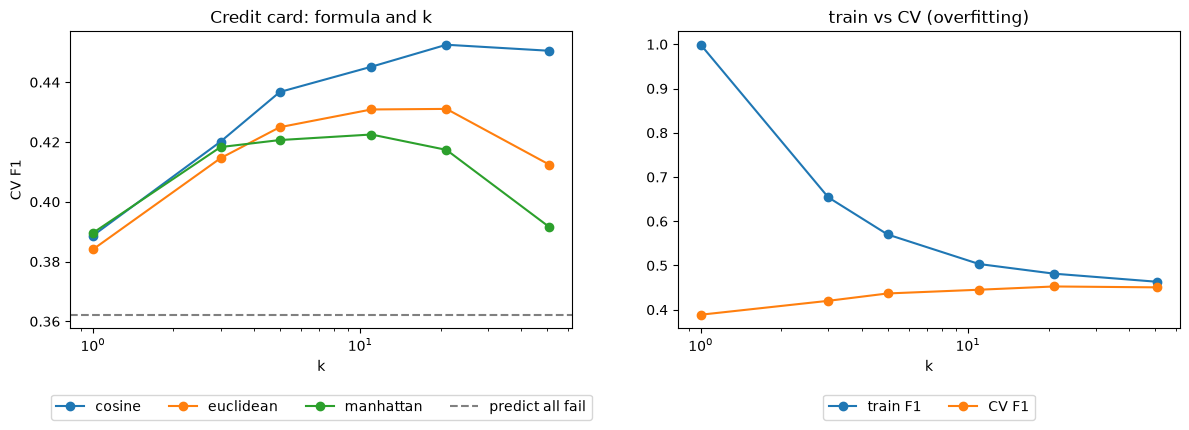

In [16]:
# grid search over distance formula and k, scaled data
grid_credit = GridSearchCV(MODEL, {'knn__metric': METRICS, 'knn__n_neighbors': KS}, cv=CV, scoring='f1', return_train_score=True).fit(X_tune_credit, y_tune_credit)
res_credit = pd.DataFrame(grid_credit.cv_results_).rename(columns={'param_knn__metric': 'formula', 'param_knn__n_neighbors': 'k', 'mean_test_score': 'CV F1',
                       'mean_train_score': 'train F1', 'std_test_score': 'CV std'})
cv_table_credit = res_credit.pivot(index='k', columns='formula', values='CV F1')
best_credit = grid_credit.best_params_
print("best:", best_credit, "| CV F1", round(grid_credit.best_score_, 3))
print(res_credit[(res_credit.formula == best_credit['knn__metric'])][['k', 'train F1', 'CV F1', 'CV std']].round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
cv_table_credit.plot(ax=axes[0], logx=True, marker='o', ylabel='CV F1', title='Credit card: formula and k')
axes[0].axhline(2 * p_credit / (1 + p_credit), color='gray', linestyle='--', label='predict all fail')
res_credit[res_credit.formula == best_credit['knn__metric']].set_index('k')[['train F1', 'CV F1']].plot(ax=axes[1], logx=True, marker='o', title='train vs CV (overfitting)')
for ax in axes:
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=4)
plt.tight_layout()
plt.show()

Student markdown:

Grid search again picks Cosine, this time with k=21 (CV F1 0.453). Unlike bankruptcy, CV F1 rises with k and then flattens: 0.39 at k=1, 0.42 at k=3, 0.44 at k=5, 0.445 at k=11, 0.453 at k=21 and 0.451 at k=51. A larger k works here because 22% of clients default, so a vote can actually pick them. Cosine also leads the other formulas from k=3 on and holds up at k=51 while Manhattan and Euclidean fall. Its CV std is about 0.01 or less, smaller than the lead, so here the formula choice is a real effect, unlike bankruptcy. Between k=21 and k=51 the CV F1 is tied (0.453 vs 0.451, within the std), so I use k=21, the peak and the smaller of the two.

Overfitting is small at the chosen k: train F1 falls from 1.0 at k=1 (perfect by construction) to 0.48 at k=21, where the gap to CV F1 (0.45) is only about 0.03.

Hypothesis A: scaling is needed for KNN.

           scaled  unscaled
manhattan   0.423     0.208
euclidean   0.431     0.154
cosine      0.453     0.143


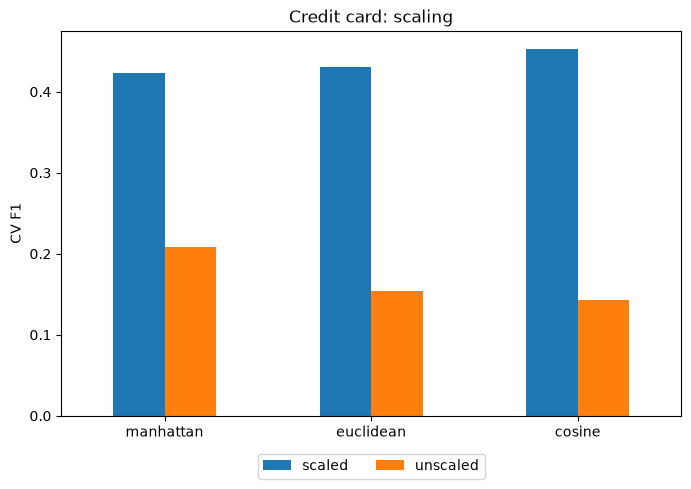

In [17]:
# each formula at its own best k, scaled (from the grid) vs not scaled
bestk_credit = cv_table_credit.idxmax()
A_credit = pd.DataFrame({'scaled': cv_table_credit.max(),
                      'unscaled': [cv_f1(X_tune_credit, y_tune_credit, m, bestk_credit[m], scale='passthrough') for m in METRICS]}, index=METRICS)
print(A_credit.round(3))
ax = A_credit.plot.bar(rot=0, figsize=(8, 5), ylabel='CV F1', title='Credit card: scaling')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=2)
plt.show()

Student markdown:

At each formula's best k, Hypothesis A shows that scaling is needed here too. Without it, F1 falls from 0.42 to 0.21 for Manhattan, from 0.43 to 0.15 for Euclidean and from 0.45 to 0.14 for Cosine. The large-scale columns (bills, payments, credit limit) dominate the distance, and the repayment status columns, which hold the real signal, barely count. Manhattan is the least hurt without scaling (0.21 vs 0.15 and 0.14), probably because it does not square the gaps, so the large-scale columns dominate a little less.

Hypothesis B: outliers hurt KNN, so capping z-scores at +/- 3 (no value counts as more than 3 standard deviations) should help, more for Euclidean (which squares each gap) than Manhattan.

           original  capped  change
manhattan     0.423   0.426   0.003
euclidean     0.431   0.435   0.004
cosine        0.453   0.451  -0.001


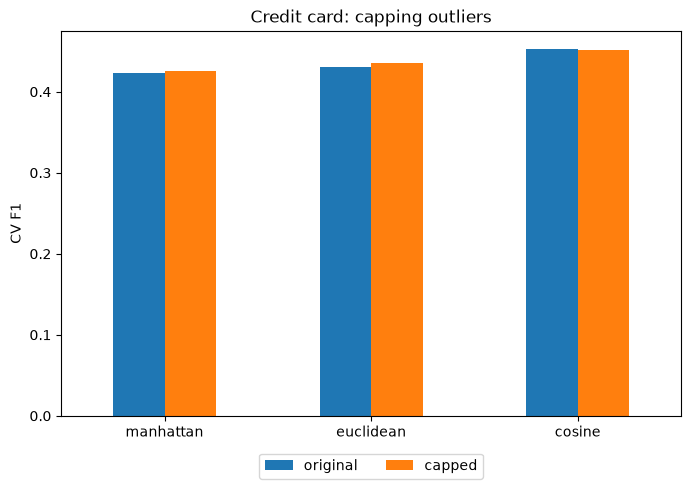

In [18]:
# same, with z-scores capped at +/- 3
B_credit = pd.Series([cv_f1(X_tune_credit, y_tune_credit, m, bestk_credit[m], cap=CAP) for m in METRICS], index=METRICS)
change_credit = pd.DataFrame({'original': A_credit['scaled'], 'capped': B_credit})
change_credit['change'] = change_credit['capped'] - change_credit['original']
print(change_credit.round(3))
ax = change_credit[['original', 'capped']].plot.bar(rot=0, figsize=(8, 5), ylabel='CV F1', title='Credit card: capping outliers')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=2)
plt.show()

Student markdown:

Hypothesis B shows that capping outliers changes almost nothing: Manhattan +0.003, Euclidean +0.004 and Cosine -0.001. This fits the EDA, since credit card has few outliers and they are not tied to default. The bankruptcy changes were larger (up to 0.03) but also within its larger noise, so for Cosine capping makes no clear difference in either dataset.

In [19]:
# final model: best CV F1 over formula and original/capped, refit on the training set, tested once on the held-out 20%
cands_credit = {(m, False): A_credit.loc[m, 'scaled'] for m in METRICS} | {(m, True): B_credit[m] for m in METRICS}
(metric_credit, capped_credit), cv_credit = max(cands_credit.items(), key=lambda kv: kv[1])
model_credit = clone(MODEL).set_params(knn__metric=metric_credit, knn__n_neighbors=bestk_credit[metric_credit], cap=CAP if capped_credit else 'passthrough').fit(X_train_credit, y_train_credit)
pred_credit = model_credit.predict(X_test_credit)
final_credit = pd.Series({'formula': metric_credit, 'capped': capped_credit, 'k': bestk_credit[metric_credit], 'CV F1': round(cv_credit, 3),
                       'test F1': f1_score(y_test_credit, pred_credit), 'precision': precision_score(y_test_credit, pred_credit),
                       'recall': recall_score(y_test_credit, pred_credit), 'F1 if all predicted fail': 2 * p_credit / (1 + p_credit)})
print(final_credit)

formula                       cosine
capped                         False
k                                 21
CV F1                          0.453
test F1                     0.449784
precision                    0.62069
recall                      0.352675
F1 if all predicted fail    0.362222
dtype: object


Student markdown:

The final model is again the best CV F1 among the formulas, with or without capping: Cosine with k=21 and no capping. On the held-out test set it reaches F1 0.450 (precision 0.621, recall 0.353) against the 0.362 baseline, about 1.2 times better. It is precise when it flags a default, but it misses about 65% of defaulters. In earlier weeks on this dataset, logistic regression reached a test F1 of 0.351 (Week 4) and the SVM 0.427 (Week 5), so KNN beats logistic regression and is close to the SVM. It trails the Week 6 decision tree (0.507) and random forest (0.531), which scored higher on the same split.

In [20]:
# top 10 features by permutation importance (shuffle one feature, see how much test F1 drops)
imp_credit = permutation_importance(model_credit, X_test_credit, y_test_credit, scoring='f1', n_repeats=2, random_state=42)
features_credit = pd.Series(imp_credit.importances_mean, index=X_test_credit.columns).nlargest(10).round(4)
print(features_credit)

repay_2005_sep    0.1391
repay_2005_aug    0.0282
repay_2005_apr    0.0187
repay_2005_jul    0.0104
repay_2005_may    0.0093
pay_2005_jul      0.0078
pay_2005_sep      0.0077
pay_2005_aug      0.0073
bill_2005_jul     0.0068
credit_limit      0.0060
dtype: float64


Student markdown:

Permutation importance, computed the same way as for bankruptcy, shows repay_2005_sep (0.139) far ahead, followed by repay_2005_aug, repay_2005_apr, repay_2005_jul and repay_2005_may.

Putting Dataset 2 together, the best model is Cosine with k=21 and no capping, with test F1 0.450 against a 0.362 baseline. k=1 overfits (train F1 1.0 vs CV 0.39), but this fades as k grows, and at k=21 the gap is only about 0.03. Most results were as expected: k=1 overfits, scaling makes a big difference (I saw this in earlier modeling too), capping barely matters, and the top features match earlier weeks.

I did not expect the best k to be as large as 21, since bankruptcy's best k was 3. So the best setting depends on the dataset. Possible reasons, which I did not test, are how common the failures are (3% vs 22%), the training size (about 5,450 vs 24,000 rows) and the number of features (95 vs 23). The other surprise is that Cosine was best again, going from the worst without scaling (0.14) to the best with it (0.45). A possible reason, which I did not test, is that the repayment, bill and payment columns across the months move together and carry similar information, so the pattern matters more than the size. The EDA helped in the same way as before: the scale gap predicted the scaling result, and the similar outlier share in both classes predicted that capping would not matter. It did not tell me which k would work.

# Both datasets compared:

In [21]:
# both datasets side by side, final model
print(pd.DataFrame({'Bankruptcy': final_bankrupt, 'Credit card': final_credit}))

                         Bankruptcy Credit card
formula                      cosine      cosine
capped                         True       False
k                                 3          21
CV F1                         0.331       0.453
test F1                    0.361111    0.449784
precision                  0.464286     0.62069
recall                     0.295455    0.352675
F1 if all predicted fail     0.0625    0.362222


Student markdown:

Both datasets were run on their full data: all 6,819 bankruptcy rows and all 30,000 credit card rows, split 80/20 into training and test sets, with every model tuned on all training rows, no sampling, and the permutation importance computed on the full test set. The table puts the two final models side by side.

| | Dataset 1: Bankruptcy | Dataset 2: Credit card |
|---|---|---|
| Best setting | Cosine, k=3, capped | Cosine, k=21, not capped |
| CV F1 | 0.331 | 0.453 |
| Test F1 (baseline) | 0.361 (0.062) | 0.450 (0.362) |
| Gain over baseline | +0.30 (about 6x) | +0.09 (about 1.2x) |
| Precision / recall | 0.464 / 0.295 | 0.621 / 0.353 |

Both datasets end up with Cosine but with very different k. Bankruptcy needs a small k (3) because a majority vote rarely picks a class that is 3% of the data, while credit card works with a larger k (21). Raw F1 is lower for bankruptcy (0.361 vs 0.450), but the baselines differ (0.062 vs 0.362), so the fair comparison is the gain over the baseline: +0.30 (about 6 times) for bankruptcy against +0.09 (about 1.2 times) for credit card. Scaling is needed in both, while capping shows no clear effect in either. Cosine is clearly best on credit card, but on bankruptcy it is only tied with the other formulas within noise.

What matters differs by dataset. For bankruptcy, k matters most (CV F1 falls from 0.30 at k=3 to 0.00 at k=51), scaling matters a lot (F1 drops of 0.16 to 0.26 without it), capping outliers gives only noisy swings (F1 moves by up to 0.03, within the noise), and the formula barely matters. For credit card, scaling matters a lot (drops of 0.21 to 0.31), the formula matters (Cosine leads beyond the noise), a large k works, and capping changes F1 by 0.004 or less. So in both datasets scaling matters much more than capping outliers, which shows no clear effect in either. For Cosine, capping moves bankruptcy up by 0.034 (within the noise) and credit card by -0.001, which is nothing.

One more surprise: I always thought bankruptcy would be the harder dataset to predict, and in raw F1 it is (0.361 vs 0.450). But once tuned, KNN improves much more over its baseline there (about 6 times, against 1.2 times for credit card), so the dataset that looks harder gains the most from a well-chosen k and scaling.

In [22]:
# top features side by side, compare with the Week 5 and Week 6 lists
pd.DataFrame({'Bankruptcy': features_bankrupt.index, 'importance 1': features_bankrupt.values,
              'Credit card': features_credit.index, 'importance 2': features_credit.values})

,Bankruptcy,importance 1,Credit card,importance 2
0,Cash Flow to Equity,0.0675,repay_2005_sep,0.1391
1,Cash Flow to Total Assets,0.0655,repay_2005_aug,0.0282
2,Net Income to Stockholder's Equity,0.0603,repay_2005_apr,0.0187
3,Current Liabilities/Liability,0.0601,repay_2005_jul,0.0104
4,Current Liability to Liability,0.0601,repay_2005_may,0.0093
5,Retained Earnings to Total Assets,0.0590,pay_2005_jul,0.0078
6,Current Liability to Current Assets,0.0547,pay_2005_sep,0.0077
7,Interest Coverage Ratio (Interest expense to E...,0.0513,pay_2005_aug,0.0073
8,Persistent EPS in the Last Four Seasons,0.0495,bill_2005_jul,0.0068
9,Quick Asset Turnover Rate,0.0472,credit_limit,0.0060


Student markdown:

Next I cross-checked these feature lists with the Week 6 tree and forest top-10 lists (Week 5 has no feature list, and Week 4's L1 logistic regression kept 74 of 95 features without a ranking). For credit card, repay_2005_sep is first and repay_2005_aug second in the Week 6 lists too, so this is very consistent. For bankruptcy it is partly consistent: Persistent EPS, Retained Earnings to Total Assets and Interest Coverage Ratio are also in Week 6 top-10 lists, and Net Income to Total Assets and Current Liability to Assets (Week 6) belong to the same families as the net income and liability ratios here. The cash flow ratios are new.

Student markdown:

Conclusion:

**Overfitting:** in both datasets k=1 overfits, because each decision rests on one neighbor and train F1 is perfect by construction (train 1.0 vs CV 0.24 for bankruptcy and 0.39 for credit card). The gap shrinks as k grows. For bankruptcy that happens because the vote stops predicting bankruptcy (CV F1 0.00 at k=51), so I stop at k=3, the CV peak. For credit card, CV F1 rises and flattens, and at k=21 the gap is only about 0.03.

**Metrics and results:** I use F1 (with precision and recall) because accuracy would hide the rare class, and I judge each model by its gain over its own predict-all-fail baseline, 2p / (1 + p), which is higher when failures are more common. Grid search tunes k, the number of neighbors that vote, and the distance formula (Manhattan, Euclidean or Cosine), which decides what "near" means. Final test F1 is 0.361 vs 0.062 for bankruptcy and 0.450 vs 0.362 for credit card. Compared with earlier weeks, KNN is not the best model: the Week 6 forest reached test F1 0.478 on bankruptcy and 0.531 on credit card.

**Expected vs. unexpected:** I expected k=1 to overfit, scaling to be needed in both datasets, and the top features to repeat from earlier weeks. I did not expect Cosine to come out best on both datasets (worst or tied for worst without scaling, best with it), or capping outliers to show no clear effect. I also did not expect the best k to differ so much between datasets (3 for bankruptcy, 21 for credit card), or tuned KNN to gain so much more over its baseline on bankruptcy, which I assumed was harder to predict. The details are in each dataset summary above.

**EDA usefulness:** the scale gap predicted the scaling result, and the share of outliers by class suggested that capping might matter more for bankruptcy, and the swings there were larger, but they were within the noise. It did not tell me which k would work. The feature importance and overfitting comparisons made sense and matched earlier weeks.

**Sources:** (add the external source(s) you used and shared on YellowDig here)

**Bigger picture, research questions:** for RQ1, credit card is driven by recent repayment status, as in Week 6, while bankruptcy shows cash flow, net income, liability and retained earnings ratios that partly repeat Week 6. For RQ2, bankruptcy is not clearly harder in every way: its F1 is lower (0.361 vs 0.450) and it needs a small k, but KNN beats its baseline about 6 times, against 1.2 times for credit card, and both datasets pick Cosine as the best setting (clearly on credit card, within noise on bankruptcy). For RQ3, the findings look fairly stable: the same top features show up across models (strongest for credit card), and scaling matters a lot in both datasets. What matters does differ by dataset: k matters most for bankruptcy, while the formula matters for credit card, and in both scaling matters far more than capping outliers, which shows no clear effect.

**How I know the conclusions are true:** the scaling effect (F1 drops of about 0.15 to 0.3) and the effect of k are much larger than the fold-to-fold variation (CV std about 0.004 to 0.06), and both repeat in both datasets. The formula differences on bankruptcy and the +0.034 Cosine gain from capping are within one std, so I treat them as hints, while Cosine's lead on credit card is larger than the std, so I treat that as real. Both datasets were tuned and tested on their full data. The test results come from one held-out split, and bankruptcy has only about 44 test failures, so its test F1 could move by several points on another split.

Summary:

| | Dataset 1: Bankruptcy | Dataset 2: Credit card |
|---|---|---|
| Best setting | Cosine, k=3, capped | Cosine, k=21 |
| Test F1 (baseline) | 0.361 (0.062) | 0.450 (0.362) |
| Gain over baseline | +0.30 (about 6x) | +0.09 (about 1.2x) |
| Precision / recall | 0.464 / 0.295 | 0.621 / 0.353 |

For bankruptcy, a small k works best because a vote rarely picks a class that is 3% of the data, and KNN is about 6 times better than its baseline. Scaling is essential, and capping outliers shows no clear effect (small swings within the noise). For credit card, a larger k (21) works because 22% of clients default. KNN is only about 1.2 times better than its baseline, and its test F1 (0.450) beats logistic regression (0.351) and is close to the SVM (0.427), but it trails the Week 6 tree (0.507) and forest (0.531). Scaling is essential here too, and capping outliers changes almost nothing. In both datasets scaling matters much more than outliers.

Both datasets were run on their full data. Across them, Cosine comes out best (clearly on credit card, within noise on bankruptcy), the same top features repeat from earlier weeks (strongest for credit card), and scaling matters in both, so the findings look fairly stable. The baseline is the F1 of predicting every row as a failure, which is higher when failures are more common, so the gain over each baseline is the fair way to compare the datasets.